In [1]:
import os
import subprocess
import sys

USER = "Drew-CSE"
REPO = "svd-image-transformation"

if os.path.exists(REPO):
    subprocess.run(["git", "-C", REPO, "pull"], check=True)
else:
    subprocess.run(
        ["git", "clone", f"https://github.com/{USER}/{REPO}.git", REPO],
        check=True
    )

sys.path.insert(0, f"{REPO}/src")
from compress import rank_k_approx

PART A: This code connects Colab to our GitHub repository and downloads or updates the project files. It then imports the rank_k_approx function from Milestone 2 so we can reuse it instead of writing it again.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

A = data.camera().astype(float)
m, n = A.shape

T = data.text().astype(float)

print("Camera:", A.shape, "Text:", T.shape)

Camera: (512, 512) Text: (172, 448)


This code loads two grayscale images, one of a cameraman and another containing text. Both are converted to floats so we can perform calculations on them. It also stores the number of rows and columns of the camera image and prints the dimensions of both images.

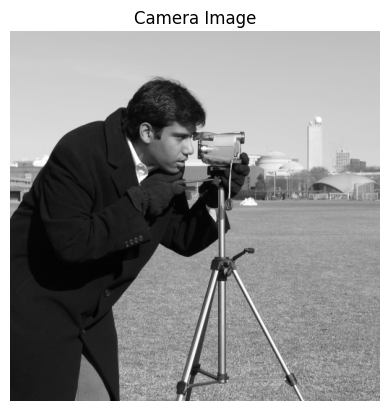

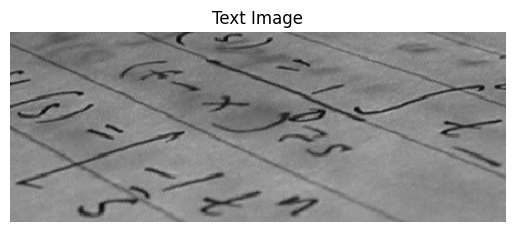

In [3]:
plt.imshow(A, cmap="gray", vmin=0, vmax=255)
plt.title("Camera Image")
plt.axis("off")
plt.show()

plt.imshow(T, cmap="gray", vmin=0, vmax=255)
plt.title("Text Image")
plt.axis("off")
plt.show()

I displayed both images to see what they look like before comparing their compression.

In [4]:
def storage(m, n, k):
    """Number of values needed to store a rank-k approximation."""
    return k * (m + n + 1)

def compression_ratio(m, n, k):
    """Original number of values divided by compressed number of values."""
    return (m * n) / storage(m, n, k)

print("Original camera values:", m * n)

for k in [1, 10, 50, 100, 255, 256]:
    print(f"k={k:3d} stored={storage(m, n, k):6d} "
          f"ratio={compression_ratio(m, n, k):.2f}")

Original camera values: 262144
k=  1 stored=  1025 ratio=255.75
k= 10 stored= 10250 ratio=25.58
k= 50 stored= 51250 ratio=5.12
k=100 stored=102500 ratio=2.56
k=255 stored=261375 ratio=1.00
k=256 stored=262400 ratio=1.00


PART B: This code calculates how many values are needed to store an image using different rank-k approximations. It then compares those amounts to the number of pixels in the original image to find the compression ratio. As k increases, more values are needed, so the compression ratio decreases. A ratio greater than 1 means the approximation uses fewer values than the original image, while a ratio less than 1 means it uses more.

In [5]:
def rel_error(A, B):
    """Relative Frobenius error when B approximates A."""
    return np.linalg.norm(A - B) / np.linalg.norm(A)

for k in [1, 5, 20, 50, 100]:
    Ak = rank_k_approx(A, k)
    print(f"k={k:3d} relative error={rel_error(A, Ak):.4f}")

k=  1 relative error=0.3604
k=  5 relative error=0.1720
k= 20 relative error=0.1012
k= 50 relative error=0.0636
k=100 relative error=0.0393


PART C: This code measures how different the rank-k approximations are from the original image using relative Frobenius error. It calculates the difference between the original and approximated matrices and divides its Frobenius norm by the norm of the original matrix. The code then tests several values of k to see how the error changes. As k increases, the relative error decreases because the approximations become closer to the original image.

In [6]:
U, s, Vt = np.linalg.svd(A, full_matrices=False)

def predicted_error(s, k):
    """Relative rank-k error computed from the singular values."""
    return np.sqrt(np.sum(s[k:]**2) / np.sum(s**2))

for k in [1, 5, 20, 50, 100]:
    actual = rel_error(A, rank_k_approx(A, k))
    predicted = predicted_error(s, k)
    print(f"k={k:3d} actual={actual:.6f} predicted={predicted:.6f}")

k=  1 actual=0.360449 predicted=0.360449
k=  5 actual=0.172014 predicted=0.172014
k= 20 actual=0.101208 predicted=0.101208
k= 50 actual=0.063565 predicted=0.063565
k=100 actual=0.039329 predicted=0.039329


PART D: This code uses the singular values from the SVD to predict the relative error of different rank-k approximations. Instead of creating each approximation to calculate the error, it uses the singular values that were left out. The code then compares this predicted error to the actual error calculated in Part C. Both methods give nearly identical results, showing that we can use singular values to determine the error without having to reconstruct the image each time.

In [7]:
ks = np.arange(1, len(s) + 1)
errors = np.array([predicted_error(s, k) for k in ks])

for target in [0.10, 0.05, 0.02, 0.01]:
    k = ks[errors <= target][0]
    ratio = compression_ratio(m, n, k)
    print(f"target={target:.2f} k={k:3d} ratio={ratio:.2f}")

target=0.10 k= 21 ratio=12.18
target=0.05 k= 73 ratio=3.50
target=0.02 k=186 ratio=1.38
target=0.01 k=263 ratio=0.97


PART E: This code finds the smallest rank needed to keep the relative error below different target values. It first calculates the predicted error for every possible rank and then finds the lowest rank that meets each target. It also calculates the compression ratio for each of those ranks to see how much storage is saved. As the target error gets smaller, a higher rank is needed to make the image more accurate, but this also reduces the amount of compression.

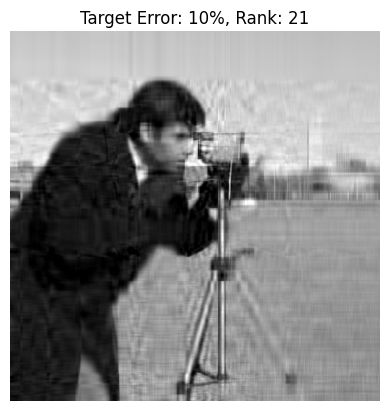

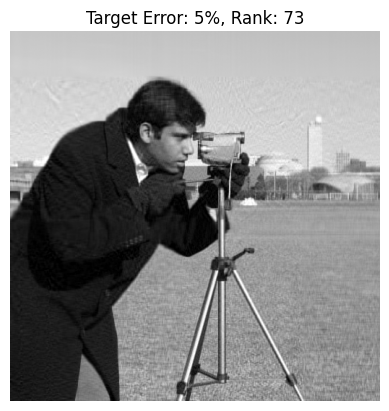

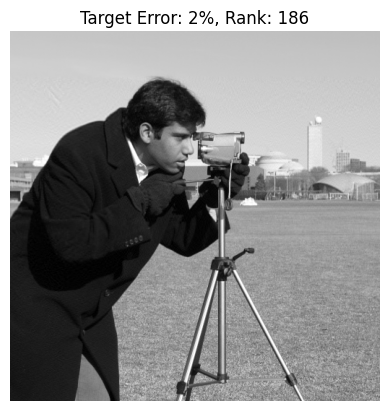

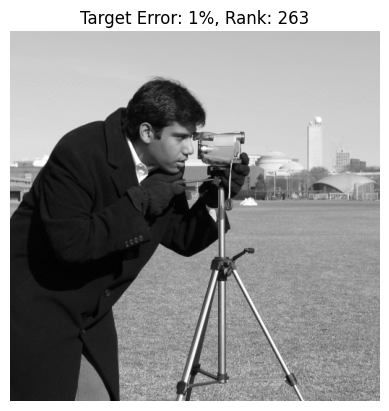

In [8]:
for target in [0.10, 0.05, 0.02, 0.01]:
    k = ks[errors <= target][0]
    Ak = np.clip(rank_k_approx(A, k), 0, 255)

    plt.imshow(Ak, cmap="gray", vmin=0, vmax=255)
    plt.title(f"Target Error: {target:.0%}, Rank: {k}")
    plt.axis("off")
    plt.show()

I also displayed the image at each target error to compare how the image quality changes. Smaller target errors require higher ranks, so the images become more detailed and closer to the original. This helps show the trade-off between image quality and the amount of compression.

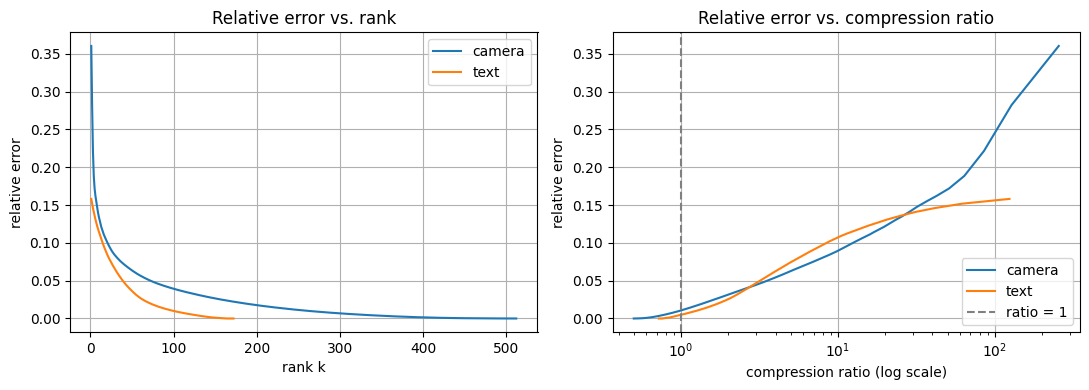

In [9]:
images = {"camera": A, "text": T}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

for name, M in images.items():
    m_img, n_img = M.shape
    s_img = np.linalg.svd(M, compute_uv=False)
    ranks = np.arange(1, len(s_img) + 1)

    errs = [predicted_error(s_img, k) for k in ranks]
    ratios = [compression_ratio(m_img, n_img, k) for k in ranks]

    ax1.plot(ranks, errs, label=name)
    ax2.semilogx(ratios, errs, label=name)

ax1.set_title("Relative error vs. rank")
ax1.set_xlabel("rank k")
ax1.set_ylabel("relative error")

ax2.axvline(1, color="gray", linestyle="--", label="ratio = 1")
ax2.set_title("Relative error vs. compression ratio")
ax2.set_xlabel("compression ratio (log scale)")
ax2.set_ylabel("relative error")

for ax in (ax1, ax2):
    ax.grid()
    ax.legend()

plt.tight_layout()
plt.savefig("error_vs_ratio.png", dpi=150)
plt.show()

PART F: This code compares how well the camera and text images can be compressed using SVD. It calculates the relative error and compression ratio for different ranks of each image and displays the results in two graphs. The first graph shows how the error decreases as rank increases, while the second shows the relationship between error and compression ratio. The dashed line at a compression ratio of 1 shows where the approximation stops saving storage compared to the original image.

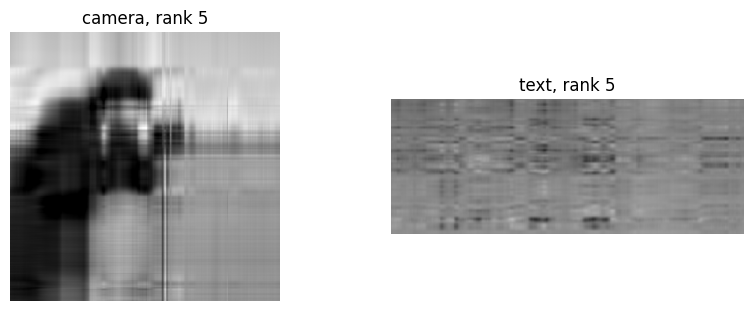

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

for ax, (name, M) in zip(axes, images.items()):
    Mk = np.clip(rank_k_approx(M, 5), 0, 255)

    ax.imshow(Mk, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{name}, rank 5")
    ax.axis("off")

plt.show()

This code displays rank-5 approximations of the camera and text images to compare their appearance. Even though both images use the same rank, they can lose different amounts of detail. This shows that relative error alone does not always tell us how useful an image is, since text can become difficult to read even when the numerical error is relatively small.

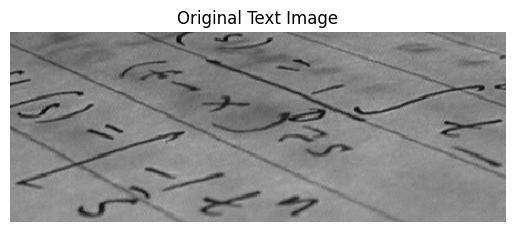

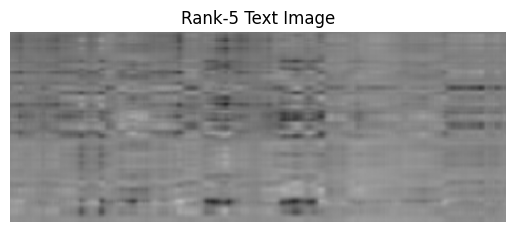

In [11]:
plt.imshow(T, cmap="gray", vmin=0, vmax=255)
plt.title("Original Text Image")
plt.axis("off")
plt.show()

plt.imshow(np.clip(rank_k_approx(T, 5), 0, 255),
           cmap="gray", vmin=0, vmax=255)
plt.title("Rank-5 Text Image")
plt.axis("off")
plt.show()

I also displayed the original text image and its rank-5 approximation separately to compare their readability. The compressed version loses some of the sharpness of the letters, which shows how reducing the rank can make text harder to read even if the overall image still looks similar.

In [12]:
A20 = rank_k_approx(A, 20)

outside = (A20 < 0) | (A20 > 255)

print("Out-of-range pixels:", outside.sum())
print("Fraction:", f"{outside.mean():.1%}")
print("Error before clipping:", round(rel_error(A, A20), 4))
print("Error after clipping:",
      round(rel_error(A, np.clip(A20, 0, 255)), 4))

Out-of-range pixels: 2634
Fraction: 1.0%
Error before clipping: 0.1012
Error after clipping: 0.1008


PART G: This code checks whether the rank-20 approximation contains any pixel values outside the grayscale range of 0 to 255. It counts how many pixels are outside that range and calculates what percentage of the image they make up. It then compares the relative error before and after clipping those values back into the valid range. Clipping cannot increase the error because the original image only contains values between 0 and 255.

Saving Spotify.png to Spotify (1).png


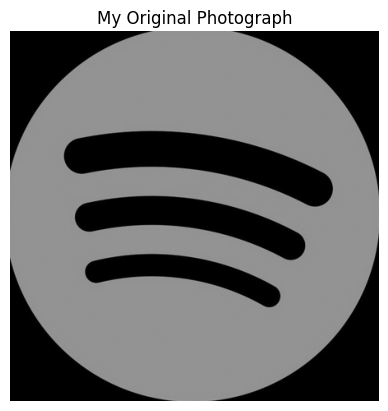

In [13]:
from google.colab import files
from PIL import Image

uploaded = files.upload()

name = list(uploaded)[0]
img = Image.open(name).convert("L")
img.thumbnail((800, 800))

P = np.array(img)

plt.imshow(P, cmap="gray", vmin=0, vmax=255)
plt.title("My Original Photograph")
plt.axis("off")
plt.show()

PART H: This code uploads the photograph I used in Milestone 1 and converts it to a grayscale image. It then resizes the image if needed and stores its pixel values in a matrix called P so I can use it for the compression calculations.

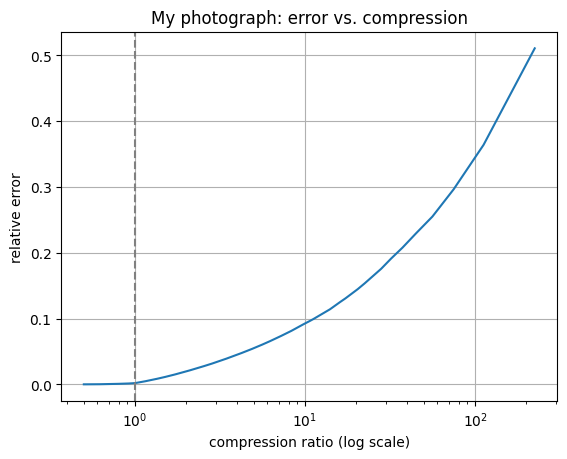

In [14]:
P_float = P.astype(float)

sp = np.linalg.svd(P_float, compute_uv=False)
kp = np.arange(1, len(sp) + 1)
ep = [predicted_error(sp, k) for k in kp]

mp, npix = P_float.shape
rp = [compression_ratio(mp, npix, k) for k in kp]

plt.semilogx(rp, ep)
plt.axvline(1, color="gray", linestyle="--")
plt.xlabel("compression ratio (log scale)")
plt.ylabel("relative error")
plt.title("My photograph: error vs. compression")
plt.grid()
plt.show()

The graph shows that as the compression ratio increases, the relative error also increases. This happens because higher compression ratios use lower ranks, meaning more information from the original image is left out. At lower compression ratios, the error remains relatively small, but it increases more quickly as the image is compressed further. This shows the trade-off between saving storage and preserving image quality.

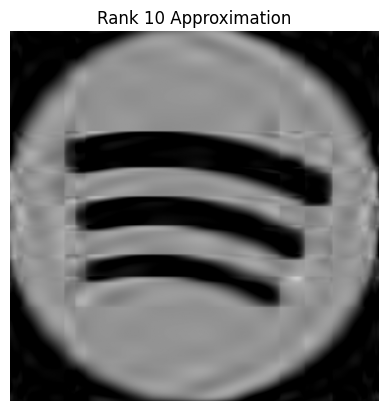

Rank: 10
Relative error: 0.1535
Compression ratio: 22.45



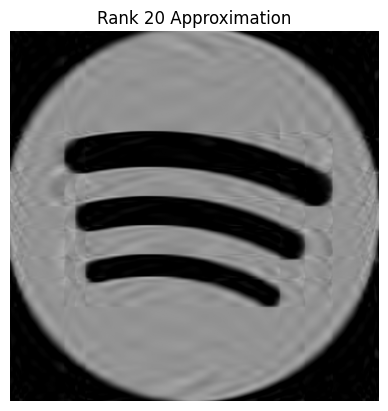

Rank: 20
Relative error: 0.0994
Compression ratio: 11.22



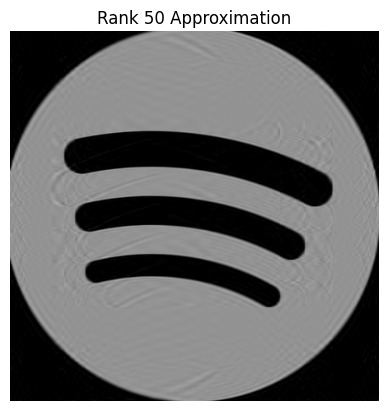

Rank: 50
Relative error: 0.0501
Compression ratio: 4.49



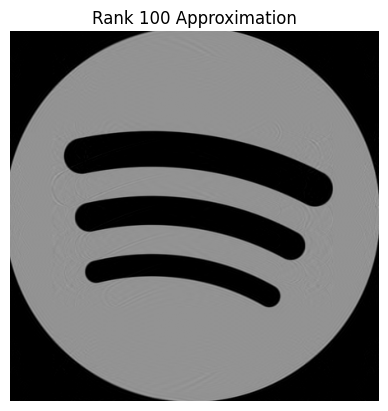

Rank: 100
Relative error: 0.0234
Compression ratio: 2.25



In [15]:
for k in [10, 20, 50, 100]:
    if k > min(P_float.shape):
        continue

    Pk = np.clip(rank_k_approx(P_float, k), 0, 255)

    plt.imshow(Pk, cmap="gray", vmin=0, vmax=255)
    plt.title(f"Rank {k} Approximation")
    plt.axis("off")
    plt.show()

    print(f"Rank: {k}")
    print(f"Relative error: {predicted_error(sp, k):.4f}")
    print(f"Compression ratio: {compression_ratio(mp, npix, k):.2f}")
    print()

I compared rank-10, rank-20, rank-50, and rank-100 approximations of my photograph. As the rank increased, the image became clearer and the relative error decreased, but the compression ratio also decreased. I chose rank 50 because the logo is still clear and recognizable, with only minor distortions around the edges. At rank 50, the relative error is 0.0501 and the compression ratio is 4.49, which provides a good balance between image quality and storage savings.